# Peringkat residual, 2017–2025

ditulis: tim PSE Atha Bintang Wahyu M. | PSE UGM

--> Historis: `TFP Provinsi 2017-2025.xlsx`. Tenaga kerja 2025 menyalin 2024. Koefisien tetap.
--> Peringkat 1 = residual tertinggi.
--> Gambar kedua: peringkat 2017 dan peringkat 2025, berkas terpisah.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
from matplotlib.patches import Patch

def find_root():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "2026bkpm.Rproj").exists():
            return cand
    return Path("/Users/athamawardi/Desktop/Research-Projects/RDSI_Kemeninves")

ROOT = find_root()
OUT = ROOT / "01 Data" / "TFP" / "output" / "eda"
OUT.mkdir(parents=True, exist_ok=True)

NAVY, CYAN, RED, TEAL, CREAM, PINK, GRAY, KERTAS = (
    "#0E2440", "#5DD0E6", "#D9042B", "#46A694", "#F2E6CE", "#F2509C", "#797F8C", "#ffffff",
)
PULAU_FILL = {
    "Sumatera": CREAM, "Jawa": PINK, "Bali-Nusra": RED,
    "Kalimantan": "#062E4C", "Sulawesi": "#30726A", "Maluku-Papua": TEAL,
}
PULAU_INK = {
    "Sumatera": "#8A6A32", "Jawa": PINK, "Bali-Nusra": RED,
    "Kalimantan": "#062E4C", "Sulawesi": "#30726A", "Maluku-Papua": TEAL,
}
PULAU_ORDER = ["Sumatera", "Jawa", "Bali-Nusra", "Kalimantan", "Sulawesi", "Maluku-Papua"]
SHORT = {
    11: "Aceh", 12: "Sumut", 13: "Sumbar", 14: "Riau", 15: "Jambi",
    16: "Sumsel", 17: "Bengkulu", 18: "Lampung", 19: "Babel", 21: "Kepri",
    31: "Jakarta", 32: "Jabar", 33: "Jateng", 34: "DIY", 35: "Jatim", 36: "Banten",
    51: "Bali", 52: "NTB", 53: "NTT",
    61: "Kalbar", 62: "Kalteng", 63: "Kalsel", 64: "Kaltim", 65: "Kaltara",
    71: "Sulut", 72: "Sulteng", 73: "Sulsel", 74: "Sultra", 75: "Gorontalo", 76: "Sulbar",
    81: "Maluku", 82: "Malut", 91: "Papua Barat", 94: "Papua",
}

rcParams.update({
    "figure.facecolor": KERTAS, "axes.facecolor": KERTAS, "axes.edgecolor": GRAY,
    "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "medium", "axes.titlecolor": NAVY, "axes.labelcolor": NAVY,
    "xtick.color": NAVY, "ytick.color": NAVY, "text.color": NAVY,
    "axes.unicode_minus": False, "legend.frameon": False,
})

def save(fig, name):
    p = OUT / name
    fig.savefig(p, dpi=150, bbox_inches="tight", facecolor=KERTAS)
    print("wrote", p.relative_to(ROOT))
    plt.show()

peta = pd.read_csv(ROOT / "01 Data" / "BKPM" / "processed" / "Dataset Provinsi(prov_name).csv")
peta = peta.dropna(subset=["Code_Prov"])
peta["Code_Prov"] = peta["Code_Prov"].astype(int)
peta["Pulau"] = peta["Pulau"].astype(str).str.strip().replace({"Bali-Nusa Tenggara": "Bali-Nusra"})


## Historis 2017–2025

Residual konstruksi. Spearman antar-tahun memakai level residual pada 34 provinsi. Angka mendekati 1 berarti urutan hampir tidak berpindah.


findfont: Failed to find font weight medium for DejaVu Sans, now using 400.
wrote 01 Data/TFP/output/eda/eda4_spearman_matriks.png
wrote 01 Data/TFP/output/eda/eda4_spearman_jalur.png
wrote 01 Data/TFP/output/eda/eda4_perubahan_peringkat_crs.png
wrote 01 Data/TFP/output/eda/eda4_bump_crs.png


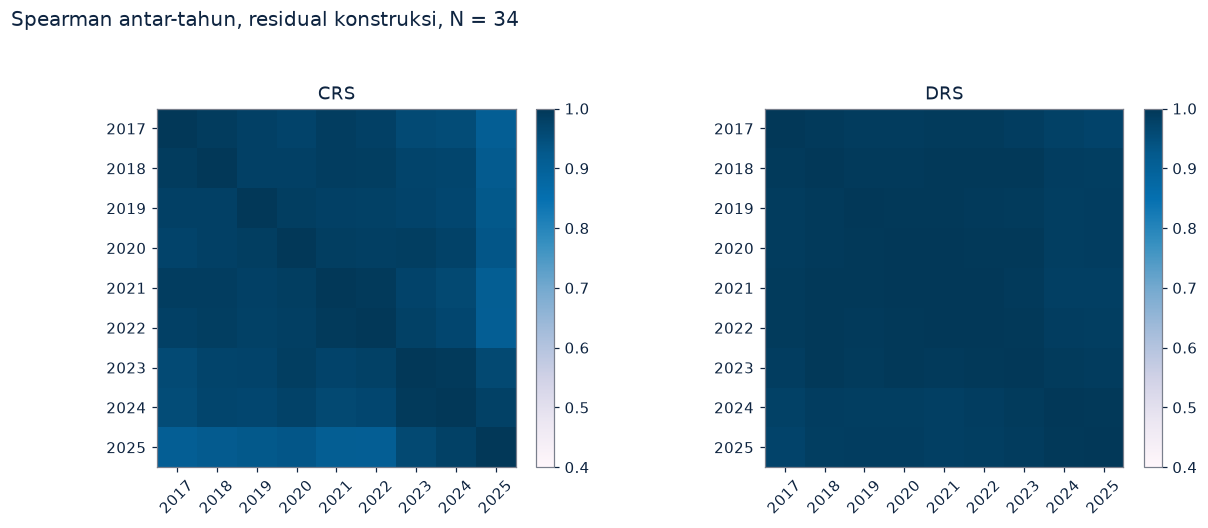

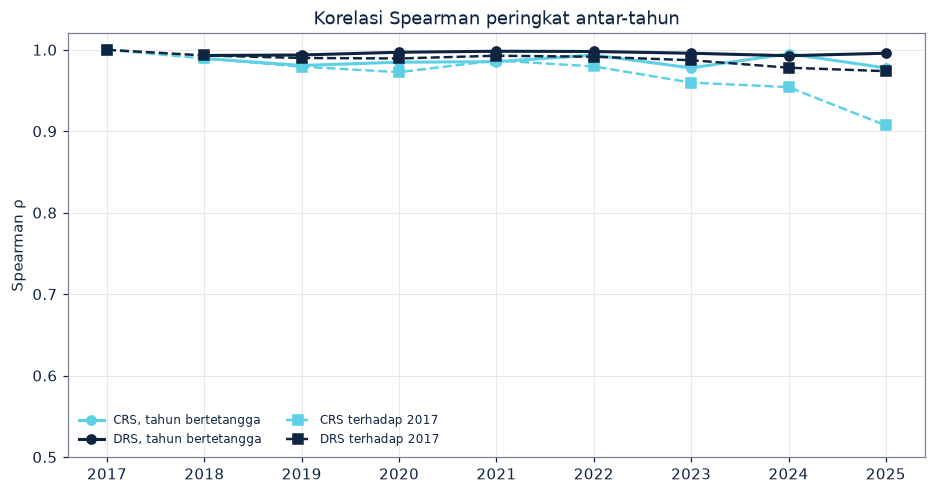

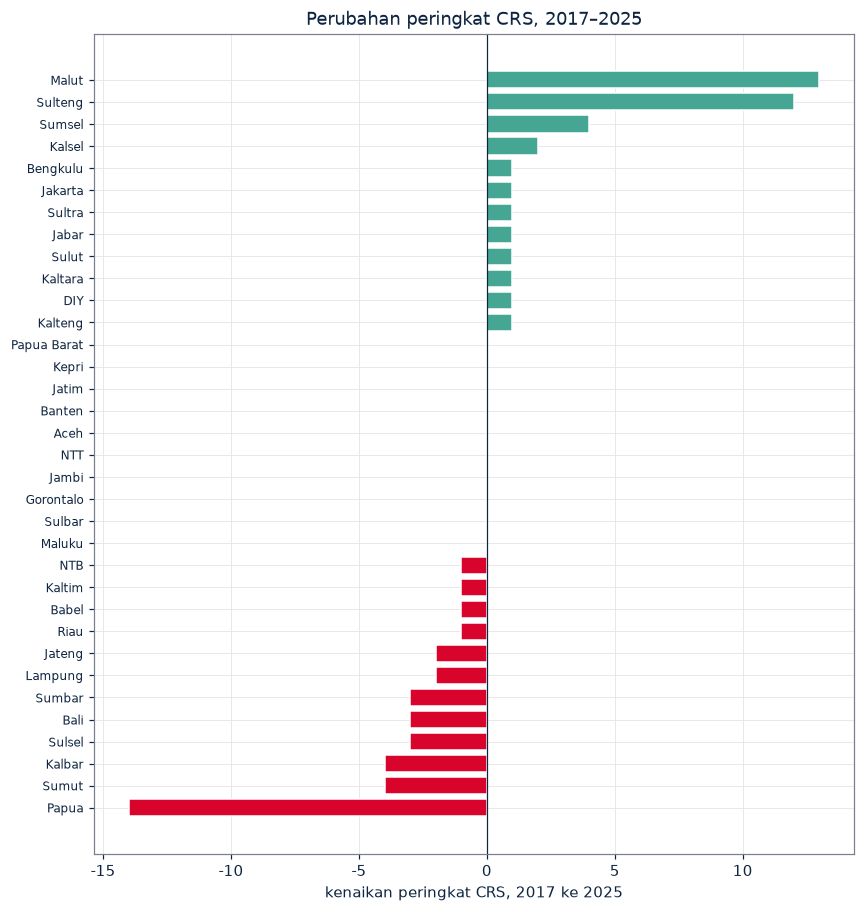

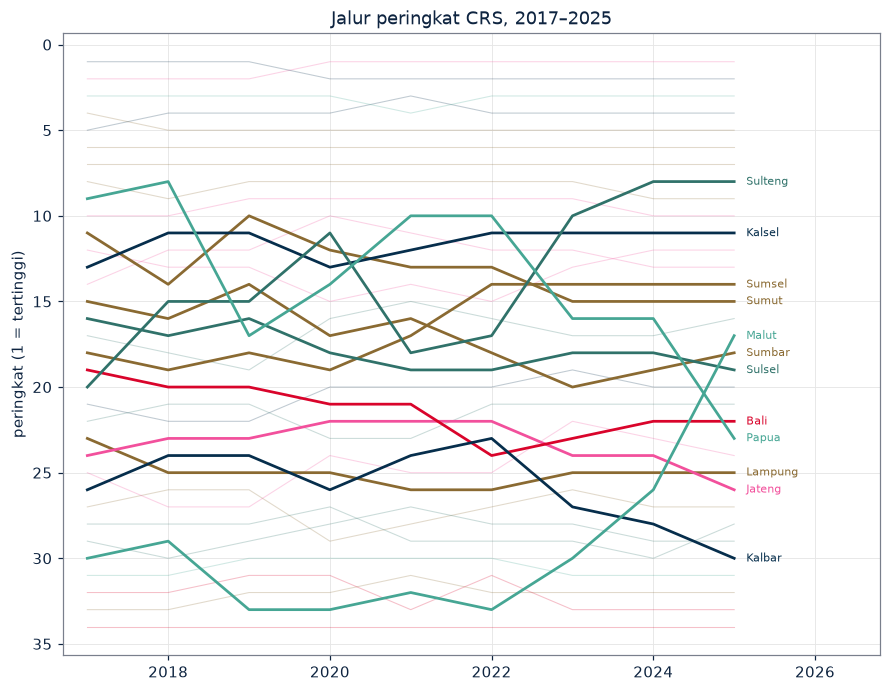

In [2]:
d = pd.read_excel(ROOT / "01 Data" / "TFP" / "output" / "konstruksi" / "TFP Provinsi 2017-2025.xlsx", sheet_name="tfp")
d["Code_Prov"] = d["Code_Prov"].astype(int)
d["Year"] = d["Year"].astype(int)
d = d.merge(peta[["Code_Prov", "Pulau"]], on="Code_Prov", how="left")
d["short"] = d["Code_Prov"].map(SHORT)
YEARS = list(range(2017, 2026))
assert set(d.Year.unique()) == set(YEARS)
assert d.Pulau.notna().all()

def wide(col):
    return d.pivot(index="Code_Prov", columns="Year", values=col).loc[:, YEARS]

def rank_wide(col):
    return wide(col).rank(ascending=False, method="average")

W_DRS, W_CRS = wide("logtfp_it"), wide("logtfp_it_crs")
R_DRS, R_CRS = rank_wide("logtfp_it"), rank_wide("logtfp_it_crs")
meta = d.drop_duplicates("Code_Prov").set_index("Code_Prov")[["short", "Pulau", "Pre_Prov"]]

S_CRS = W_CRS.corr(method="spearman")
S_DRS = W_DRS.corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.8))
for ax, S, title in zip(axes, [S_CRS, S_DRS], ["CRS", "DRS"]):
    im = ax.imshow(S.to_numpy(), vmin=0.4, vmax=1, cmap="PuBu", origin="upper")
    ax.set_xticks(range(len(YEARS)))
    ax.set_yticks(range(len(YEARS)))
    ax.set_xticklabels(YEARS, rotation=45)
    ax.set_yticklabels(YEARS)
    ax.set_title(title)
    ax.grid(False)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.suptitle("Spearman antar-tahun, residual konstruksi, N = 34", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.93))
save(fig, "eda4_spearman_matriks.png")

adj_crs = [S_CRS.loc[y, y + 1] for y in YEARS[:-1]]
adj_drs = [S_DRS.loc[y, y + 1] for y in YEARS[:-1]]
anchor_crs = [S_CRS.loc[2017, y] for y in YEARS]
anchor_drs = [S_DRS.loc[2017, y] for y in YEARS]
fig, ax = plt.subplots(figsize=(8.6, 4.6))
ax.plot(YEARS[1:], adj_crs, color=CYAN, lw=2, marker="o", label="CRS, tahun bertetangga")
ax.plot(YEARS[1:], adj_drs, color=NAVY, lw=2, marker="o", label="DRS, tahun bertetangga")
ax.plot(YEARS, anchor_crs, color=CYAN, lw=1.6, ls="--", marker="s", label="CRS terhadap 2017")
ax.plot(YEARS, anchor_drs, color=NAVY, lw=1.6, ls="--", marker="s", label="DRS terhadap 2017")
ax.set_ylim(0.5, 1.02)
ax.set_ylabel("Spearman ρ")
ax.set_title("Korelasi Spearman peringkat antar-tahun")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
save(fig, "eda4_spearman_jalur.png")

chg = (R_CRS[2017] - R_CRS[2025]).rename("naik")
chg = chg.reset_index()
chg["short"] = chg["Code_Prov"].map(SHORT)
chg = chg.sort_values("naik")
fig, ax = plt.subplots(figsize=(8, 8.4))
colors = [TEAL if v > 0 else RED if v < 0 else GRAY for v in chg["naik"]]
ax.barh(chg["short"], chg["naik"], color=colors, edgecolor="white", height=0.78)
ax.axvline(0, color=NAVY, lw=0.8)
ax.set_xlabel("kenaikan peringkat CRS, 2017 ke 2025")
ax.set_title("Perubahan peringkat CRS, 2017–2025")
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
save(fig, "eda4_perubahan_peringkat_crs.png")

movers = chg.reindex(chg["naik"].abs().sort_values(ascending=False).index).head(12)
mover_codes = set(movers["Code_Prov"])
fig, ax = plt.subplots(figsize=(8.2, 6.4))
for code, row in R_CRS.iterrows():
    hot = code in mover_codes
    ax.plot(YEARS, row.values, color=PULAU_INK[meta.loc[code, "Pulau"]], lw=1.8 if hot else 0.7,
            alpha=1 if hot else 0.25, zorder=3 if hot else 1)
    if hot:
        ax.text(2025.15, row[2025], SHORT[code], va="center", fontsize=7, color=PULAU_INK[meta.loc[code, "Pulau"]])
ax.set_xlim(2016.7, 2026.8)
ax.invert_yaxis()
ax.set_ylabel("peringkat (1 = tertinggi)")
ax.set_title("Jalur peringkat CRS, 2017–2025")
fig.tight_layout()
save(fig, "eda4_bump_crs.png")


## DRS terhadap CRS, rata-rata 2017–2025

Selisih = peringkat DRS − peringkat CRS. Positif berarti daerah itu lebih tinggi setelah ukuran dikeluarkan.


wrote 01 Data/TFP/output/eda/eda4_drs_crs_dumbbell.png
wrote 01 Data/TFP/output/eda/eda4_drs_crs_gap.png
wrote 01 Data/TFP/output/eda/eda4_drs_crs_scatter.png
wrote 01 Data/TFP/output/eda/eda4_drs_crs_pulau.png
wrote 01 Data/TFP/output/eda/eda4_spearman_drs_crs.png


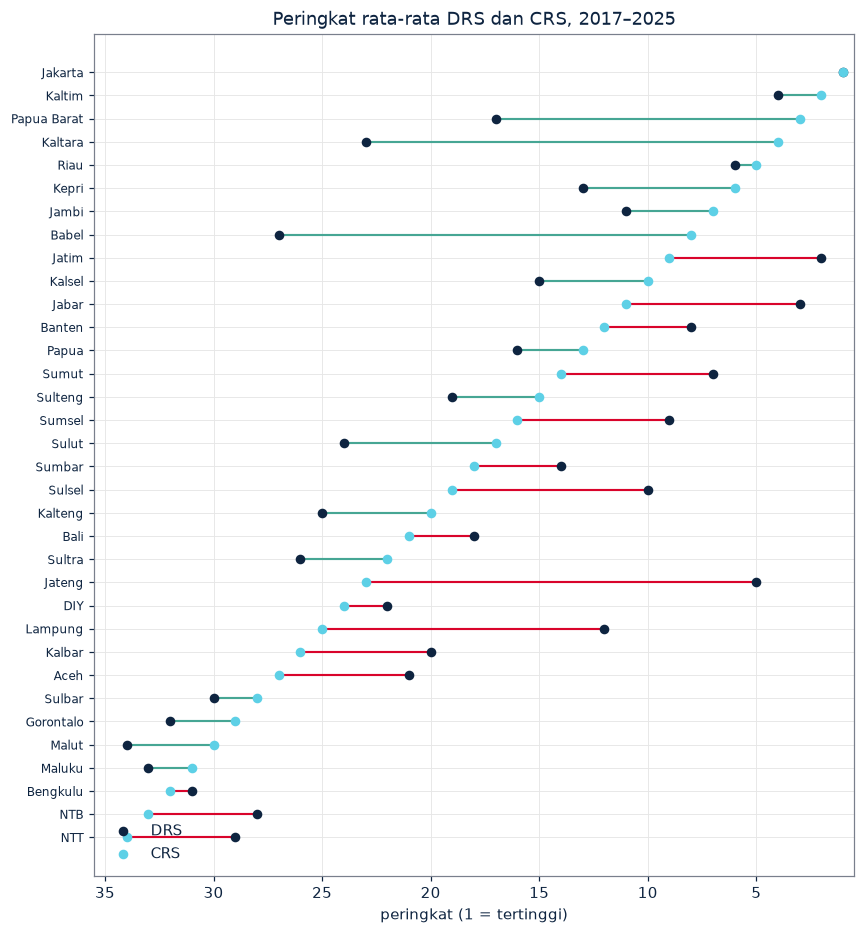

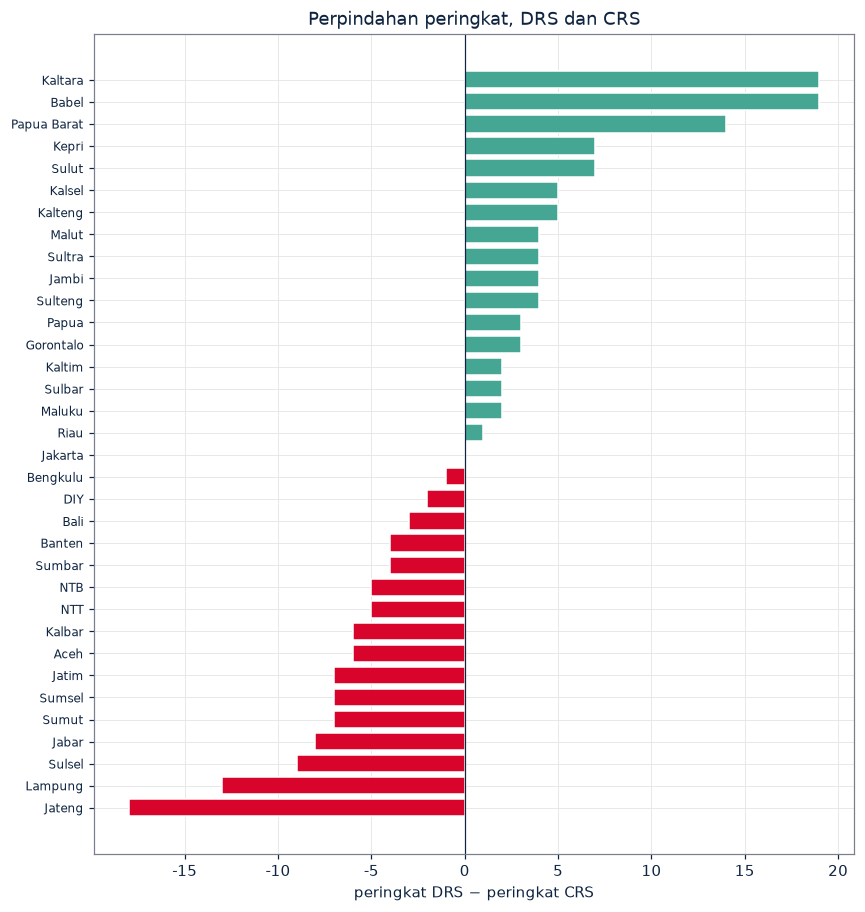

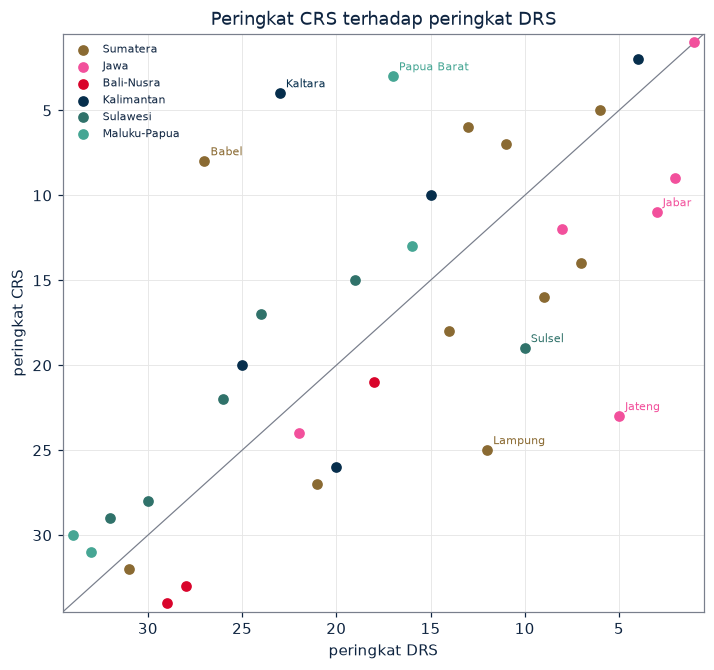

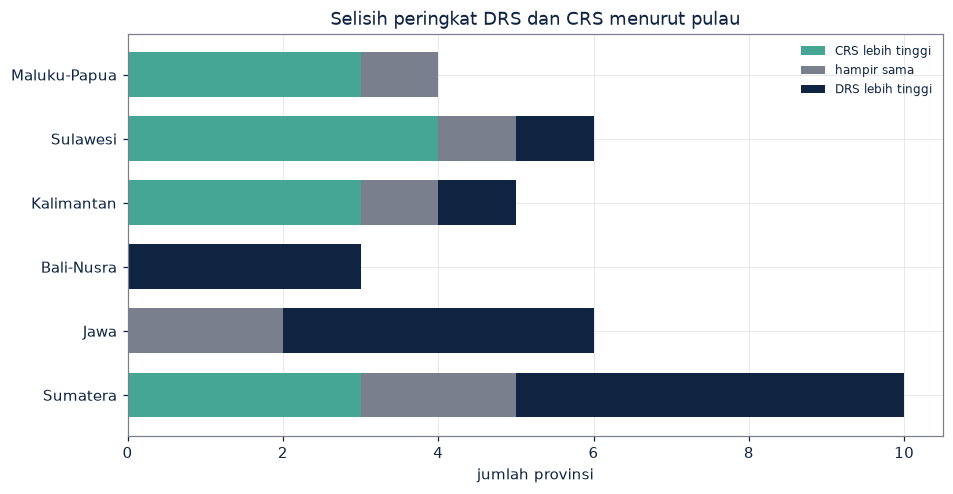

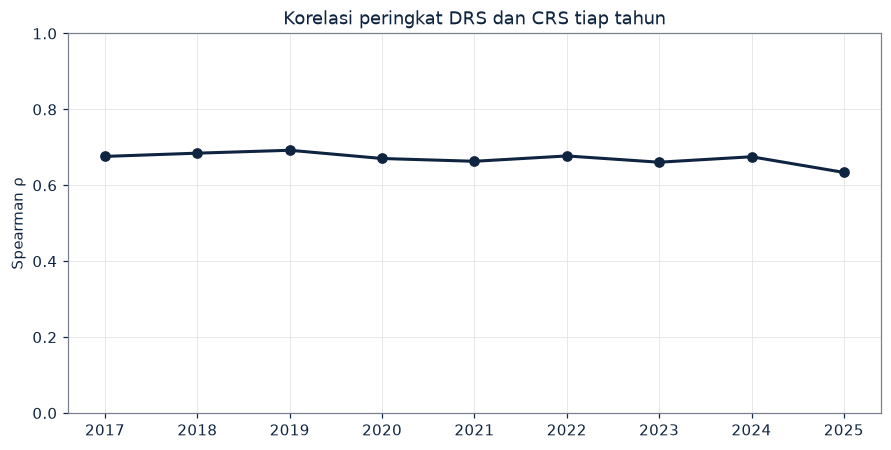

In [3]:
mean = d.groupby("Code_Prov")[["logtfp_it", "logtfp_it_crs"]].mean()
cmp = meta.copy()
cmp["rank_drs"] = mean["logtfp_it"].rank(ascending=False, method="average")
cmp["rank_crs"] = mean["logtfp_it_crs"].rank(ascending=False, method="average")
cmp["gap"] = cmp["rank_drs"] - cmp["rank_crs"]
rho_levels = mean["logtfp_it"].corr(mean["logtfp_it_crs"], method="spearman")

order = cmp.sort_values("rank_crs", ascending=False)
fig, ax = plt.subplots(figsize=(8, 8.6))
for code, r in order.iterrows():
    color = TEAL if r.gap > 0 else RED if r.gap < 0 else GRAY
    ax.plot([r.rank_drs, r.rank_crs], [r.short, r.short], color=color, lw=1.4, zorder=1)
ax.scatter(order["rank_drs"], order["short"], s=28, color=NAVY, label="DRS", zorder=3)
ax.scatter(order["rank_crs"], order["short"], s=28, color=CYAN, label="CRS", zorder=3)
ax.set_xlabel("peringkat (1 = tertinggi)")
ax.set_xlim(35.5, 0.5)
ax.set_title("Peringkat rata-rata DRS dan CRS, 2017–2025")
ax.tick_params(axis="y", labelsize=8)
ax.legend(loc="lower left")
fig.tight_layout()
save(fig, "eda4_drs_crs_dumbbell.png")

gap = cmp.sort_values("gap")
fig, ax = plt.subplots(figsize=(8, 8.4))
colors = [TEAL if v > 0 else RED if v < 0 else GRAY for v in gap["gap"]]
ax.barh(gap["short"], gap["gap"], color=colors, edgecolor="white", height=0.78)
ax.axvline(0, color=NAVY, lw=0.8)
ax.set_xlabel("peringkat DRS − peringkat CRS")
ax.set_title("Perpindahan peringkat, DRS dan CRS")
ax.tick_params(axis="y", labelsize=8)
fig.tight_layout()
save(fig, "eda4_drs_crs_gap.png")

fig, ax = plt.subplots(figsize=(6.6, 6.2))
for p in PULAU_ORDER:
    sub = cmp[cmp.Pulau == p]
    ax.scatter(sub["rank_drs"], sub["rank_crs"], s=36, color=PULAU_INK[p], label=p, zorder=3)
    for code, r in sub.iterrows():
        if abs(r.gap) >= 8:
            ax.annotate(r.short, (r.rank_drs, r.rank_crs), fontsize=7, color=PULAU_INK[p],
                        xytext=(4, 4), textcoords="offset points")
lim = [0.5, 34.5]
ax.plot(lim, lim, color=GRAY, lw=0.8)
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.invert_xaxis()
ax.invert_yaxis()
ax.set_xlabel("peringkat DRS")
ax.set_ylabel("peringkat CRS")
ax.set_title("Peringkat CRS terhadap peringkat DRS")
ax.legend(fontsize=7, loc="upper left")
fig.tight_layout()
save(fig, "eda4_drs_crs_scatter.png")

def grup(v):
    if v >= 3:
        return "CRS lebih tinggi"
    if v <= -3:
        return "DRS lebih tinggi"
    return "hampir sama"

cmp["grup"] = cmp["gap"].map(grup)
counts = (cmp.groupby(["Pulau", "grup"]).size()
          .unstack(fill_value=0)
          .reindex(PULAU_ORDER)
          .reindex(columns=["CRS lebih tinggi", "hampir sama", "DRS lebih tinggi"]))
fig, ax = plt.subplots(figsize=(8.8, 4.6))
left = np.zeros(len(PULAU_ORDER))
for col, color in [("CRS lebih tinggi", TEAL), ("hampir sama", GRAY), ("DRS lebih tinggi", NAVY)]:
    ax.barh(PULAU_ORDER, counts[col], left=left, color=color, label=col, height=0.7)
    left = left + counts[col].to_numpy()
ax.set_xlabel("jumlah provinsi")
ax.set_title("Selisih peringkat DRS dan CRS menurut pulau")
ax.legend(fontsize=8)
fig.tight_layout()
save(fig, "eda4_drs_crs_pulau.png")

rho_year = [W_DRS[y].corr(W_CRS[y], method="spearman") for y in YEARS]
fig, ax = plt.subplots(figsize=(8.2, 4.2))
ax.plot(YEARS, rho_year, color=NAVY, lw=2, marker="o")
ax.set_ylim(0, 1)
ax.set_ylabel("Spearman ρ")
ax.set_title("Korelasi peringkat DRS dan CRS tiap tahun")
fig.tight_layout()
save(fig, "eda4_spearman_drs_crs.png")


## Kiri 2017, kanan 2025


wrote 01 Data/TFP/output/eda/eda4_slope_crs_2017_2025.png
wrote 01 Data/TFP/output/eda/eda4_slope_drs_2017_2025.png
wrote 01 Data/TFP/output/eda/eda4_drs_crs_2017_2025.png
wrote 01 Data/TFP/output/eda/eda4_gap_drs_crs_2017_2025.png


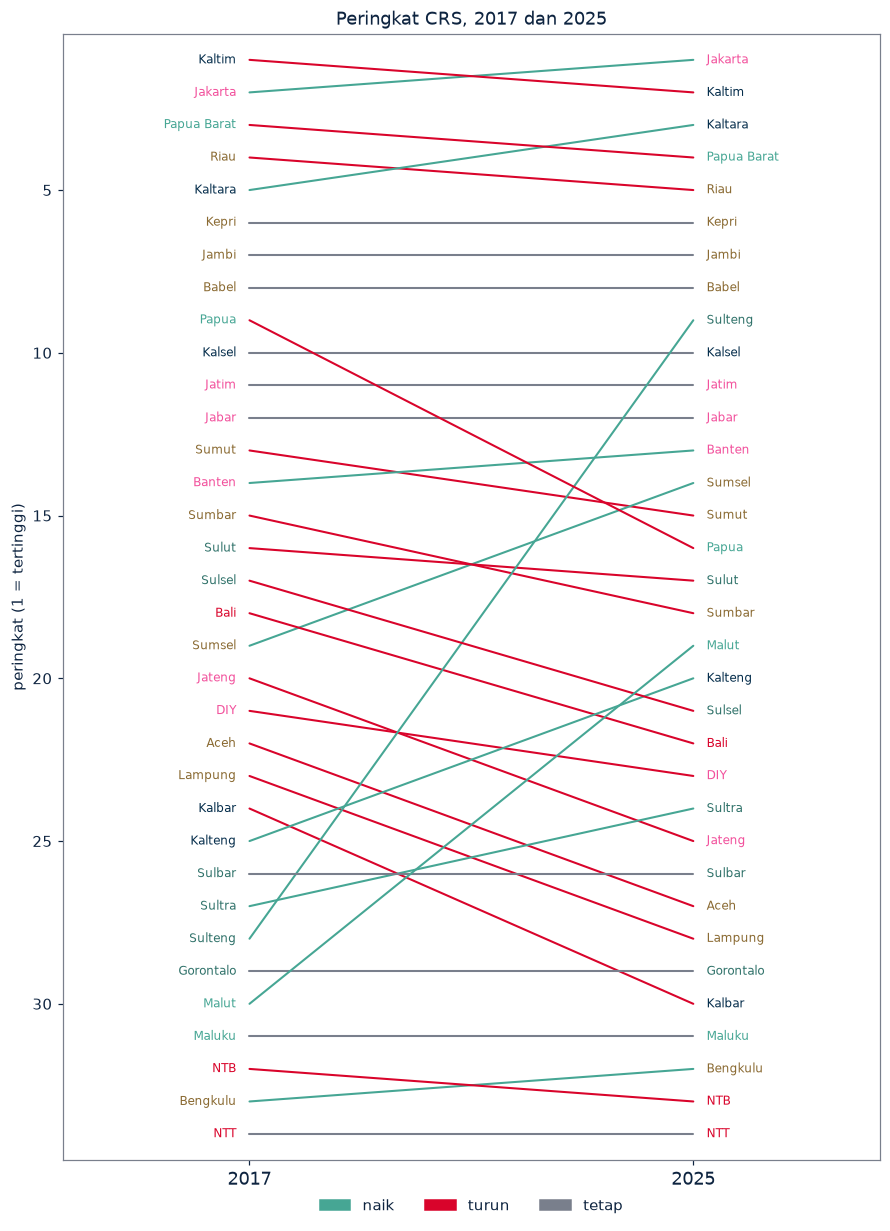

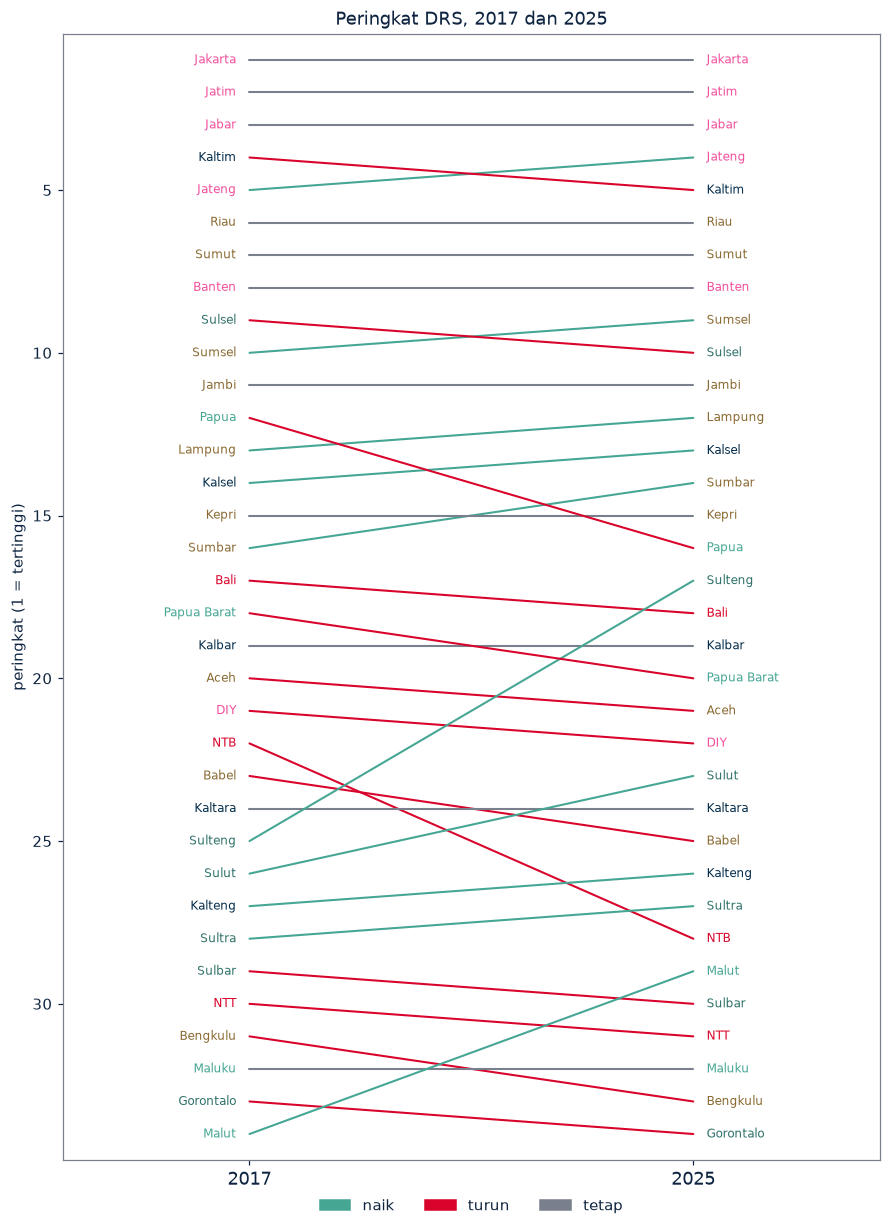

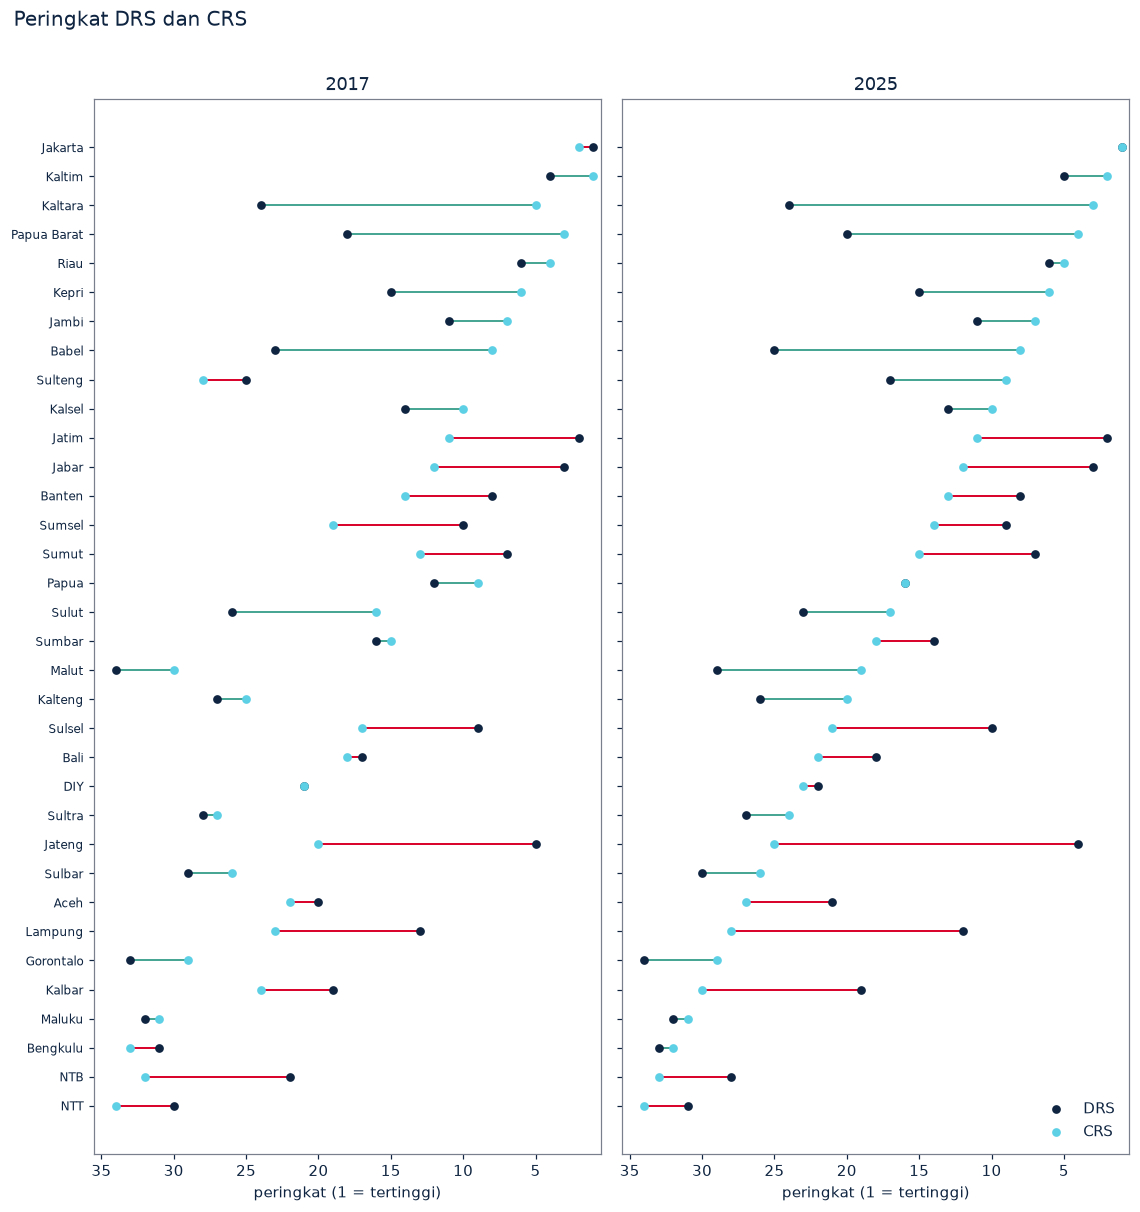

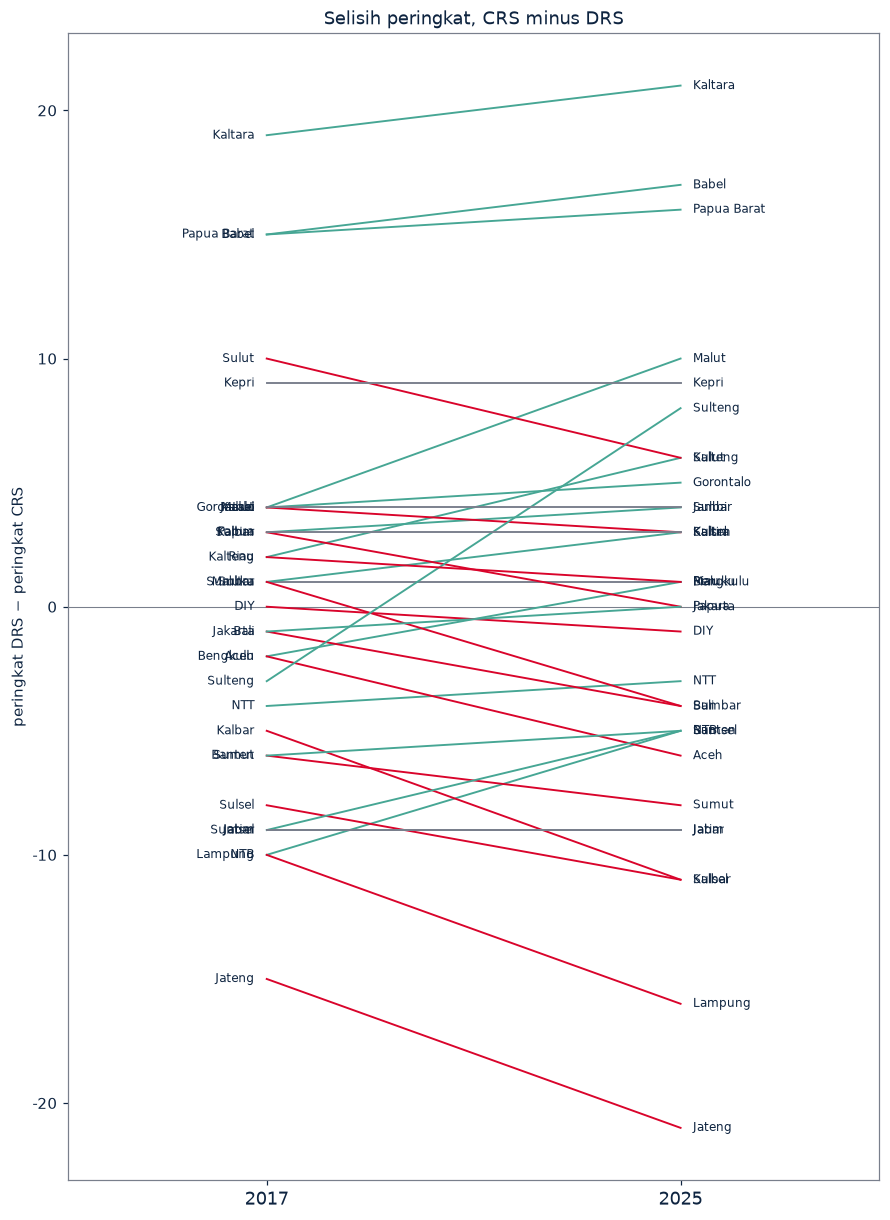

In [4]:
raw = pd.read_excel(
    ROOT / "01 Data" / "TFP" / "processed" / "Predicted Value TFP 2017-2025.xlsx",
    sheet_name="ADHK",
)
raw = raw[raw["Year"].isin([2017, 2025])].copy()
raw["Code_Prov"] = raw["Code_Prov"].astype(int)
raw["Year"] = raw["Year"].astype(int)
raw = raw.merge(peta[["Code_Prov", "Pulau"]], on="Code_Prov", how="left")
assert raw.groupby("Year").size().to_dict() == {2017: 34, 2025: 34}

def endpoint_ranks(col):
    w = raw.pivot(index="Code_Prov", columns="Year", values=col)
    return w.rank(ascending=False, method="average")

E_CRS = endpoint_ranks("logtfp_it_crs")
E_DRS = endpoint_ranks("logtfp_it")
rho_crs = raw.pivot(index="Code_Prov", columns="Year", values="logtfp_it_crs")[2017].corr(
    raw.pivot(index="Code_Prov", columns="Year", values="logtfp_it_crs")[2025], method="spearman")
rho_drs = raw.pivot(index="Code_Prov", columns="Year", values="logtfp_it")[2017].corr(
    raw.pivot(index="Code_Prov", columns="Year", values="logtfp_it")[2025], method="spearman")
pulau_e = raw.drop_duplicates("Code_Prov").set_index("Code_Prov")["Pulau"]

def slope(ranks, title, fname):
    fig, ax = plt.subplots(figsize=(8.2, 11.2))
    ax.grid(False)
    for code, row in ranks.iterrows():
        y0, y1 = float(row[2017]), float(row[2025])
        if y1 < y0 - 0.1:
            color = TEAL
        elif y1 > y0 + 0.1:
            color = RED
        else:
            color = GRAY
        ax.plot([0, 1], [y0, y1], color=color, lw=1.35, solid_capstyle="round", zorder=2)
        ink = PULAU_INK[pulau_e.loc[code]]
        ax.text(-0.03, y0, SHORT[code], ha="right", va="center", fontsize=8, color=ink)
        ax.text(1.03, y1, SHORT[code], ha="left", va="center", fontsize=8, color=ink)
    ax.set_xlim(-0.42, 1.42)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["2017", "2025"], fontsize=12)
    ax.set_ylim(34.8, 0.2)
    ax.set_ylabel("peringkat (1 = tertinggi)")
    ax.set_title(title)
    ax.legend(handles=[
        Patch(color=TEAL, label="naik"),
        Patch(color=RED, label="turun"),
        Patch(color=GRAY, label="tetap"),
    ], loc="lower center", bbox_to_anchor=(0.5, -0.06), ncol=3)
    fig.tight_layout()
    save(fig, fname)

slope(E_CRS, "Peringkat CRS, 2017 dan 2025", "eda4_slope_crs_2017_2025.png")
slope(E_DRS, "Peringkat DRS, 2017 dan 2025", "eda4_slope_drs_2017_2025.png")

def side(year):
    out = pd.DataFrame({"rank_drs": E_DRS[year], "rank_crs": E_CRS[year]})
    out["gap"] = out["rank_drs"] - out["rank_crs"]
    out["short"] = out.index.map(SHORT)
    return out

s2017, s2025 = side(2017), side(2025)
names = s2025.sort_values("rank_crs", ascending=False)["short"].tolist()

fig, axes = plt.subplots(1, 2, figsize=(10.5, 11.2), sharey=True)
for ax, snap, year in zip(axes, [s2017, s2025], [2017, 2025]):
    ax.grid(False)
    snap = snap.set_index("short").loc[names]
    for name, r in snap.iterrows():
        color = TEAL if r.gap > 0.1 else RED if r.gap < -0.1 else GRAY
        ax.plot([r.rank_drs, r.rank_crs], [name, name], color=color, lw=1.3, zorder=1)
    ax.scatter(snap["rank_drs"], snap.index, s=22, color=NAVY, zorder=3, label="DRS")
    ax.scatter(snap["rank_crs"], snap.index, s=22, color=CYAN, zorder=3, label="CRS")
    ax.set_xlim(35.5, 0.5)
    ax.set_xlabel("peringkat (1 = tertinggi)")
    ax.set_title(str(year))
axes[0].tick_params(axis="y", labelsize=8)
axes[1].legend(loc="lower right")
fig.suptitle("Peringkat DRS dan CRS", x=0.02, ha="left", fontsize=13, color=NAVY)
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "eda4_drs_crs_2017_2025.png")

fig, ax = plt.subplots(figsize=(8.2, 11.2))
ax.grid(False)
g0 = s2017.set_index("short").loc[names, "gap"]
g1 = s2025.set_index("short").loc[names, "gap"]
for name in names:
    y0, y1 = float(g0[name]), float(g1[name])
    color = TEAL if y1 > y0 + 0.1 else RED if y1 < y0 - 0.1 else GRAY
    ax.plot([0, 1], [y0, y1], color=color, lw=1.25, zorder=2)
    ax.text(-0.03, y0, name, ha="right", va="center", fontsize=8, color=NAVY)
    ax.text(1.03, y1, name, ha="left", va="center", fontsize=8, color=NAVY)
ax.axhline(0, color=GRAY, lw=0.7, zorder=1)
ax.set_xlim(-0.48, 1.48)
ax.set_xticks([0, 1])
ax.set_xticklabels(["2017", "2025"], fontsize=12)
ax.set_ylabel("peringkat DRS − peringkat CRS")
ax.set_title("Selisih peringkat, CRS minus DRS")
fig.tight_layout()
save(fig, "eda4_gap_drs_crs_2017_2025.png")
